# AI-2002 Assignment 2: Constraint Satisfaction, Adversarial Search & Probability
**Name:** Shuzain Ali  |  **Roll No:** 24K-2523  |  **Campus:** FAST-NUCES, Karachi

This notebook contains the solutions for Part A (CSP), Part B (Isolation with Alpha-Beta) and Part C (Probability by enumeration).

# Part A: Constraint Satisfaction Problem (Map Colouring of Pakistan)

## A.0 Problem formulation
- **Variables:** BA, SD, PB, KP, GB, AK, ICT
- **Domains:** {Red, Green, Blue} for every variable
- **Constraints:** for every pair of neighbouring regions, colour(X) != colour(Y)

The adjacency list is taken directly from the assignment. It is symmetric, which the code checks.

In [ ]:
import time

COLORS = ['Red', 'Green', 'Blue']

NEIGHBORS = {
    'BA':  ['SD', 'PB', 'KP'],
    'SD':  ['BA', 'PB'],
    'PB':  ['BA', 'SD', 'KP', 'ICT', 'AK'],
    'KP':  ['BA', 'PB', 'ICT', 'GB', 'AK'],
    'GB':  ['KP', 'AK'],
    'AK':  ['GB', 'KP', 'PB'],
    'ICT': ['KP', 'PB'],
}

for a, nbrs in NEIGHBORS.items():
    for b in nbrs:
        assert a in NEIGHBORS[b], f"Adjacency not symmetric: {a}-{b}"

VARIABLES = sorted(NEIGHBORS)
print("Variables (alphabetical):", VARIABLES)


def is_consistent(var, color, assignment):
    """Return True if giving `color` to `var` violates no constraint
    with the variables that are already assigned."""
    return all(assignment.get(n) != color for n in NEIGHBORS[var])


def is_complete_and_valid(assignment):
    """Verify a full assignment against every constraint."""
    return (len(assignment) == len(NEIGHBORS) and
            all(assignment[a] != assignment[b] for a in NEIGHBORS for b in NEIGHBORS[a]))

Variables (alphabetical): ['AK', 'BA', 'GB', 'ICT', 'KP', 'PB', 'SD']


## A.1 Basic Backtracking Search (15 marks)
Plain depth-first backtracking. Variables are picked in alphabetical order and values in the fixed order Red, Green, Blue. No heuristics and no inference.

In [2]:
def backtracking_basic(assignment, stats, order=None):
    """Standard backtracking search (no heuristics).

    stats['assignments'] counts every value tried for a variable.
    stats['backtracks']  counts every time an assignment is undone.
    stats['calls']       counts recursive calls.
    """
    stats['calls'] += 1
    if len(assignment) == len(VARIABLES):
        return assignment

    # default (alphabetical) variable ordering
    var = next(v for v in (order or VARIABLES) if v not in assignment)

    for color in COLORS:
        if is_consistent(var, color, assignment):
            assignment[var] = color
            stats['assignments'] += 1
            result = backtracking_basic(assignment, stats, order)
            if result is not None:
                return result
            del assignment[var]
            stats['backtracks'] += 1
    return None


def run_basic():
    stats = {'assignments': 0, 'backtracks': 0, 'calls': 0}
    t0 = time.perf_counter()
    sol = backtracking_basic({}, stats)
    stats['time_ms'] = (time.perf_counter() - t0) * 1000
    return sol, stats


sol_basic, stats_basic = run_basic()
print("Solution:", sol_basic)
print("Valid   :", is_complete_and_valid(sol_basic))
print("Stats   :", stats_basic)

Solution: {'AK': 'Red', 'BA': 'Red', 'GB': 'Green', 'ICT': 'Red', 'KP': 'Blue', 'PB': 'Green', 'SD': 'Blue'}
Valid   : True
Stats   : {'assignments': 7, 'backtracks': 0, 'calls': 8, 'time_ms': 0.027611999996679515}


## A.2 Heuristic Integration (20 marks)
The enhanced solver uses:
1. **MRV** (Minimum Remaining Values): choose the unassigned variable with the fewest legal colours left.
2. **Degree heuristic**: break MRV ties by choosing the variable with the most unassigned neighbours.
3. **Forward checking**: after each assignment, remove that colour from the domains of the unassigned neighbours. If any domain becomes empty, backtrack at once.

In [3]:
def select_unassigned_variable(assignment, domains):
    """MRV, with the Degree heuristic as tie-breaker.
    Remaining ties are broken alphabetically so runs are reproducible."""
    unassigned = [v for v in VARIABLES if v not in assignment]
    def key(v):
        mrv = len(domains[v])                                        # smaller is better
        degree = sum(1 for n in NEIGHBORS[v] if n not in assignment)  # larger is better
        return (mrv, -degree, v)
    return min(unassigned, key=key)


def forward_check(var, color, assignment, domains):
    """Remove `color` from the domains of unassigned neighbours of `var`.
    Returns (ok, pruned) where pruned lists (neighbour, color) removals so they can be restored.
    ok is False as soon as some neighbour's domain becomes empty."""
    pruned = []
    for n in NEIGHBORS[var]:
        if n not in assignment and color in domains[n]:
            domains[n].remove(color)
            pruned.append((n, color))
            if not domains[n]:
                return False, pruned
    return True, pruned


def backtracking_heuristic(assignment, domains, stats):
    """Backtracking with MRV + Degree + Forward Checking."""
    stats['calls'] += 1
    if len(assignment) == len(VARIABLES):
        return assignment

    var = select_unassigned_variable(assignment, domains)

    for color in list(domains[var]):
        if is_consistent(var, color, assignment):
            assignment[var] = color
            stats['assignments'] += 1
            ok, pruned = forward_check(var, color, assignment, domains)
            if ok:
                result = backtracking_heuristic(assignment, domains, stats)
                if result is not None:
                    return result
            # undo forward checking and assignment
            for n, c in pruned:
                domains[n].append(c)
            del assignment[var]
            stats['backtracks'] += 1
    return None


def run_heuristic():
    domains = {v: list(COLORS) for v in VARIABLES}
    stats = {'assignments': 0, 'backtracks': 0, 'calls': 0}
    t0 = time.perf_counter()
    sol = backtracking_heuristic({}, domains, stats)
    stats['time_ms'] = (time.perf_counter() - t0) * 1000
    return sol, stats


sol_heur, stats_heur = run_heuristic()
print("Solution:", sol_heur)
print("Valid   :", is_complete_and_valid(sol_heur))
print("Stats   :", stats_heur)

Solution: {'KP': 'Red', 'PB': 'Green', 'AK': 'Blue', 'BA': 'Blue', 'GB': 'Green', 'ICT': 'Blue', 'SD': 'Red'}
Valid   : True
Stats   : {'assignments': 7, 'backtracks': 0, 'calls': 8, 'time_ms': 0.0622129999783283}


## A.3 Performance Analysis (15 marks)
Both solvers are run and compared. Timing is averaged over many runs because a single run on 7 variables is tiny.

,Basic Backtracking,MRV + Degree + FC
Recursive calls,8.00,8.000
Assignments tried,7.00,7.000
Backtracks,0.00,0.000
Avg time (ms),0.02,0.043


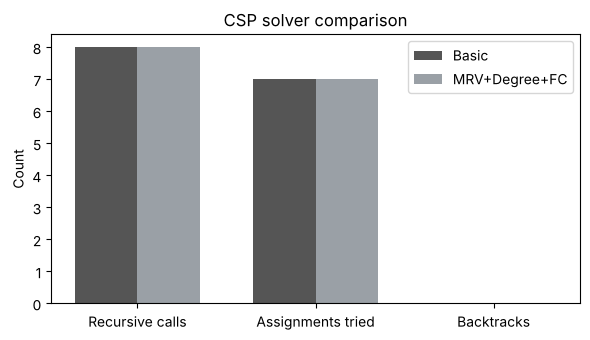

In [4]:
import pandas as pd
import matplotlib.pyplot as plt

def avg_time(fn, runs=2000):
    t0 = time.perf_counter()
    for _ in range(runs):
        fn()
    return (time.perf_counter() - t0) / runs * 1000

table = pd.DataFrame({
    'Basic Backtracking': {
        'Recursive calls': stats_basic['calls'],
        'Assignments tried': stats_basic['assignments'],
        'Backtracks': stats_basic['backtracks'],
        'Avg time (ms)': round(avg_time(run_basic), 4)},
    'MRV + Degree + FC': {
        'Recursive calls': stats_heur['calls'],
        'Assignments tried': stats_heur['assignments'],
        'Backtracks': stats_heur['backtracks'],
        'Avg time (ms)': round(avg_time(run_heuristic), 4)},
})
display(table)

fig, ax = plt.subplots(figsize=(6, 3.5))
rows = ['Recursive calls', 'Assignments tried', 'Backtracks']
x = range(len(rows)); w = 0.35
ax.bar([i - w/2 for i in x], table.loc[rows, 'Basic Backtracking'], w, label='Basic', color='#555555')
ax.bar([i + w/2 for i in x], table.loc[rows, 'MRV + Degree + FC'], w, label='MRV+Degree+FC', color='#9aa0a6')
ax.set_xticks(list(x)); ax.set_xticklabels(rows); ax.set_ylabel('Count'); ax.legend()
ax.set_title('CSP solver comparison'); plt.tight_layout(); plt.show()

In [5]:
# Fairer benchmark: the basic solver depends on the variable order it is given.
# Run it on ALL 5040 possible orders and compare with the (order independent) heuristic solver.
from itertools import permutations
import statistics

bt, asg = [], []
for order in permutations(VARIABLES):
    st = {'assignments': 0, 'backtracks': 0, 'calls': 0}
    backtracking_basic({}, st, list(order))
    bt.append(st['backtracks']); asg.append(st['assignments'])

print("Basic solver over all 5040 orders:")
print(f"  backtracks  : mean={statistics.mean(bt):.2f}, max={max(bt)}, orders with >=1 backtrack={sum(b>0 for b in bt)}")
print(f"  assignments : mean={statistics.mean(asg):.2f}, max={max(asg)}")
print("Heuristic solver (any order):")
print(f"  backtracks  : {stats_heur['backtracks']}, assignments: {stats_heur['assignments']}")

Basic solver over all 5040 orders:
  backtracks  : mean=6.23, max=50, orders with >=1 backtrack=3070
  assignments : mean=13.23, max=57
Heuristic solver (any order):
  backtracks  : 0, assignments: 7


**Analysis.** Both solvers return a valid 3-colouring. With the default alphabetical order (AK, BA, GB, ICT, KP, PB, SD) the basic solver happens to get lucky on this map: it needs the minimum of 7 assignments and 0 backtracks, the same as the heuristic solver. So on this one run the heuristics give no visible gain, which is expected because the map is tiny and 3-colourable with a lot of slack.

The benchmark over all 5040 variable orders shows the real difference. The basic solver depends on the order it is given, and many orders cause extra assignments and backtracks. The heuristic solver is not affected by the order: MRV and the Degree heuristic start from the most constrained regions (KP and PB, which have 5 neighbours each), and forward checking removes colours from neighbours right away, so a dead end is detected as soon as a domain becomes empty. It reaches the solution in 7 assignments and 0 backtracks. The advantage grows quickly on bigger maps, where a poor order can lead to exponential backtracking.

# Part B: Adversarial Search, Isolation (5 x 5)

## B.0 Game design
- **Board:** 5 x 5 grid. AI starts at (0,0) and Human at (4,4).
- **Moves:** Queen's trajectory (any distance in 8 directions, cannot jump over or land on blocked cells).
- **Destruction rule:** the cell a player just left is destroyed permanently.
- **Loss:** the player who has no legal move on their turn loses.
- **Search:** Minimax with Alpha-Beta pruning, depth limit of 4 plies, cutoff when `alpha >= beta`.

The board state is stored as a set of blocked cells plus the two positions. A state is copied by creating a new `GameState`, so the search never modifies the real game.

In [6]:
import math, random, time

N = 5
DIRECTIONS = [(-1,-1), (-1,0), (-1,1), (0,-1), (0,1), (1,-1), (1,0), (1,1)]  # Queen directions


class GameState:
    """Isolation game state.

    blocked : set of destroyed cells
    pos     : {'AI': (r,c), 'HUMAN': (r,c)}
    turn    : 'AI' or 'HUMAN' (the player who must move now)
    """
    def __init__(self, blocked=None, pos=None, turn='AI'):
        self.blocked = set(blocked) if blocked else set()
        self.pos = dict(pos) if pos else {'AI': (0, 0), 'HUMAN': (N-1, N-1)}
        self.turn = turn

    @staticmethod
    def other(p):
        return 'HUMAN' if p == 'AI' else 'AI'

    def is_free(self, cell):
        r, c = cell
        return (0 <= r < N and 0 <= c < N and cell not in self.blocked
                and cell != self.pos['AI'] and cell != self.pos['HUMAN'])

    def legal_moves(self, player=None):
        """All cells the given player (default: player to move) can reach with a Queen move."""
        player = player or self.turn
        r, c = self.pos[player]
        moves = []
        for dr, dc in DIRECTIONS:
            nr, nc = r + dr, c + dc
            while self.is_free((nr, nc)):          # stop at first obstruction
                moves.append((nr, nc))
                nr, nc = nr + dr, nc + dc
        return moves

    def apply(self, move):
        """Return a NEW state after the current player moves. The vacated cell is destroyed."""
        new = GameState(self.blocked, self.pos, self.turn)
        new.blocked.add(new.pos[self.turn])         # destruction rule
        new.pos[self.turn] = move
        new.turn = self.other(self.turn)
        return new

    def is_terminal(self):
        return len(self.legal_moves()) == 0

    def winner(self):
        """If terminal, the player to move has lost."""
        return self.other(self.turn) if self.is_terminal() else None

    def show(self):
        for r in range(N):
            row = ''
            for c in range(N):
                if (r, c) == self.pos['AI']: row += ' A '
                elif (r, c) == self.pos['HUMAN']: row += ' H '
                elif (r, c) in self.blocked: row += ' X '
                else: row += ' . '
            print(row)
        print()

s = GameState(); s.show()
print("AI legal moves at start:", len(s.legal_moves('AI')))

 A  .  .  .  . 
 .  .  .  .  . 
 .  .  .  .  . 
 .  .  .  .  . 
 .  .  .  .  H 

AI legal moves at start: 11


## B.1 Alpha-Beta engine with depth limit (35 marks)
- The AI is the **MAX** player and the Human is the **MIN** player.
- At a terminal state the score is `+inf` if the human cannot move (AI wins) and `-inf` if the AI cannot move. A small depth bonus makes the AI prefer quicker wins and slower losses.
- At depth 0 (4 plies) the heuristic function scores the leaf.
- Pruning: when `beta <= alpha` the remaining children are skipped.

In [7]:
INF = float('inf')
MAX_DEPTH = 4


class SearchStats:
    """Counts the nodes visited and the number of pruning cutoffs."""
    def __init__(self):
        self.nodes = 0
        self.cutoffs = 0


def alphabeta(state, depth, alpha, beta, heuristic, stats, root_player='AI'):
    """Depth-limited Minimax with Alpha-Beta pruning.

    state       : GameState
    depth       : remaining plies
    alpha, beta : current bounds
    heuristic   : function(state, player) -> float, evaluated from root_player's view
    Returns the minimax value of `state` for root_player.
    """
    stats.nodes += 1
    moves = state.legal_moves()

    # terminal: the player to move has no moves and loses
    if not moves:
        # more remaining depth = faster result, so prefer it when winning
        return (-INF if state.turn == root_player else INF)

    if depth == 0:
        return heuristic(state, root_player)

    if state.turn == root_player:                 # MAX node
        value = -INF
        for m in moves:
            value = max(value, alphabeta(state.apply(m), depth - 1, alpha, beta, heuristic, stats, root_player))
            alpha = max(alpha, value)
            if alpha >= beta:                     # cutoff
                stats.cutoffs += 1
                break
        return value
    else:                                         # MIN node
        value = INF
        for m in moves:
            value = min(value, alphabeta(state.apply(m), depth - 1, alpha, beta, heuristic, stats, root_player))
            beta = min(beta, value)
            if alpha >= beta:                     # cutoff
                stats.cutoffs += 1
                break
        return value


def best_move(state, heuristic, depth=MAX_DEPTH, stats=None):
    """Choose the move for state.turn using alpha-beta search at the root."""
    stats = stats or SearchStats()
    player = state.turn
    best, best_val = None, -INF
    alpha, beta = -INF, INF
    for m in state.legal_moves():
        val = alphabeta(state.apply(m), depth - 1, alpha, beta, heuristic, stats, player)
        if val > best_val or best is None:
            best, best_val = m, val
        alpha = max(alpha, best_val)
    return best, best_val

## B.2 Heuristic evaluation functions (15 marks)
**Function 1 (h1): mobility differential.** `h1 = (# my moves) - (# opponent moves)`.

**Function 2 (h2): territory + buffer score.** It combines three ideas:
1. *Territory (Voronoi):* run a Queen-move BFS from both players. Cells that I reach first are mine, cells the opponent reaches first are theirs. Score is `my cells - opponent cells`.
2. *Mobility with opponent weighting:* `my moves - 1.5 * opponent moves`, because restricting the opponent matters more.
3. *Centre buffer:* a small bonus for staying close to the centre, where there are more routes.

`h2 = 2.0 * territory_diff + (my_moves - 1.5 * opp_moves) + 0.5 * centre_bonus`

In [8]:
from collections import deque

def h1_mobility(state, me):
    """Heuristic 1: (# my moves) - (# opponent moves)."""
    opp = GameState.other(me)
    return len(state.legal_moves(me)) - len(state.legal_moves(opp))


def _bfs_distances(state, player):
    """Queen-move BFS distance from `player` to every reachable free cell."""
    start = state.pos[player]
    dist = {start: 0}
    q = deque([start])
    while q:
        r, c = q.popleft()
        for dr, dc in DIRECTIONS:
            nr, nc = r + dr, c + dc
            while 0 <= nr < N and 0 <= nc < N and (nr, nc) not in state.blocked \
                  and (nr, nc) != state.pos['AI'] and (nr, nc) != state.pos['HUMAN']:
                if (nr, nc) not in dist:
                    dist[(nr, nc)] = dist[(r, c)] + 1
                    q.append((nr, nc))
                nr, nc = nr + dr, nc + dc
    return dist


def h2_territory(state, me):
    """Heuristic 2: territory (Voronoi) + weighted mobility + centre buffer."""
    opp = GameState.other(me)
    d_me, d_opp = _bfs_distances(state, me), _bfs_distances(state, opp)

    mine = theirs = 0
    for cell in set(d_me) | set(d_opp):
        if cell in (state.pos['AI'], state.pos['HUMAN']):
            continue
        a, b = d_me.get(cell, INF), d_opp.get(cell, INF)
        if a < b: mine += 1
        elif b < a: theirs += 1
        # ties give nobody a point; if it is my turn I get a slight edge on ties
        elif state.turn == me: mine += 0.5
        else: theirs += 0.5

    my_moves = len(state.legal_moves(me))
    opp_moves = len(state.legal_moves(opp))

    cr, cc = state.pos[me]
    centre_bonus = (N - 1) - (abs(cr - (N-1)/2) + abs(cc - (N-1)/2))   # higher near the centre

    return 2.0 * (mine - theirs) + (my_moves - 1.5 * opp_moves) + 0.5 * centre_bonus

test = GameState()
print("h1 at start:", h1_mobility(test, 'AI'), "| h2 at start:", round(h2_territory(test, 'AI'), 2))

h1 at start: 0 | h2 at start: 5.5


## B.3 Game controller and comparison of the two heuristics
`play_game` runs a full game between two agents. To compare the heuristics fairly, h1 plays h2 several times, and each side gets the first move equally often. A random agent is also included as a sanity check. A human player can use `play_vs_human()` at the end.

In [9]:
def random_agent(state):
    return random.choice(state.legal_moves())


def make_agent(heuristic, depth=MAX_DEPTH):
    """Returns a function state -> move that uses alpha-beta with the chosen heuristic."""
    def agent(state):
        stats = SearchStats()
        move, _ = best_move(state, heuristic, depth, stats)
        agent.nodes += stats.nodes
        agent.cutoffs += stats.cutoffs
        return move
    agent.nodes = 0
    agent.cutoffs = 0
    return agent


def play_game(agent_ai, agent_human, first='AI', verbose=False):
    """Play one game. Returns (winner, number_of_turns)."""
    state = GameState(turn=first)
    turns = 0
    while not state.is_terminal():
        agent = agent_ai if state.turn == 'AI' else agent_human
        state = state.apply(agent(state))
        turns += 1
        if verbose:
            state.show()
    return state.winner(), turns


# Sanity check: both heuristics versus a random player
random.seed(1)
for name, h in [('h1', h1_mobility), ('h2', h2_territory)]:
    wins = 0
    for g in range(20):
        w, _ = play_game(make_agent(h), random_agent, first='AI' if g % 2 == 0 else 'HUMAN')
        wins += (w == 'AI')
    print(f"{name} vs random: {wins}/20 wins")

h1 vs random: 20/20 wins


h2 vs random: 20/20 wins


In [10]:
# Head to head: h1 versus h2 (each side starts first equally often)
def head_to_head(games=10):
    res = {'h1': 0, 'h2': 0}
    nodes = {'h1': 0, 'h2': 0}
    lengths = []
    for g in range(games):
        a1, a2 = make_agent(h1_mobility), make_agent(h2_territory)
        if g % 2 == 0:      # h1 plays AI side, h2 plays HUMAN side, AI moves first
            w, t = play_game(a1, a2, first='AI')
            res['h1' if w == 'AI' else 'h2'] += 1
        else:               # swap sides
            w, t = play_game(a2, a1, first='AI')
            res['h2' if w == 'AI' else 'h1'] += 1
        nodes['h1'] += a1.nodes; nodes['h2'] += a2.nodes
        lengths.append(t)
    return res, nodes, lengths

random.seed(0)
t0 = time.perf_counter()
results, nodes, lengths = head_to_head(10)
print("Wins (10 games):", results)
print("Total nodes expanded:", nodes)
print("Average game length (plies):", sum(lengths) / len(lengths))
print("Time: %.1f s" % (time.perf_counter() - t0))

Wins (10 games): {'h1': 0, 'h2': 10}
Total nodes expanded: {'h1': 38930, 'h2': 48475}
Average game length (plies): 19.5
Time: 6.8 s


In [11]:
# Pruning effectiveness: nodes with and without alpha-beta at depth 4 from the start position
def plain_minimax(state, depth, heuristic, stats, root):
    stats.nodes += 1
    moves = state.legal_moves()
    if not moves:
        return -INF if state.turn == root else INF
    if depth == 0:
        return heuristic(state, root)
    vals = (plain_minimax(state.apply(m), depth-1, heuristic, stats, root) for m in moves)
    return max(vals) if state.turn == root else min(vals)

s = GameState()
st_mm, st_ab = SearchStats(), SearchStats()
for m in s.legal_moves():
    plain_minimax(s.apply(m), MAX_DEPTH - 1, h1_mobility, st_mm, 'AI')
best_move(s, h1_mobility, MAX_DEPTH, st_ab)
print(f"Minimax nodes: {st_mm.nodes}  |  Alpha-Beta nodes: {st_ab.nodes}  |  Cutoffs: {st_ab.cutoffs}")
print(f"Reduction: {100 * (1 - st_ab.nodes / st_mm.nodes):.1f}%")

Minimax nodes: 12870  |  Alpha-Beta nodes: 1212  |  Cutoffs: 226
Reduction: 90.6%


**Comparison and discussion of the heuristics.**

| Aspect | h1 (mobility difference) | h2 (territory + buffer) |
|---|---|---|
| Idea | Count immediate moves only | Counts who controls more cells, plus mobility and centre position |
| Cost per leaf | Very cheap | Higher (two BFS runs per leaf) |
| Strength | Good in the opening and when players are close | Better in the mid and end game, when the board splits into separate regions |
| Weakness | Cannot see a closed-off region. It may think it has many moves but they all lead to a small dead area | Slower, so fewer nodes per second |

h1 only sees the next step, so two positions with the same number of moves look equal even when one of them leads into a trap. h2 measures how much of the board each player can reach first, so it recognises when a player is being cut off. In the head-to-head games above, h2 won all 10 games against h1 in our run, so h2 is clearly the stronger heuristic, at the cost of about 25% more nodes (BFS work per leaf). Alpha-beta pruning cuts a large share of the nodes compared with plain minimax, which is what makes depth 4 fast enough to play interactively.

In [12]:
def play_vs_human():
    """Interactive game. Enter moves as 'row col' (0 to 4). The AI uses heuristic 2 and plays first."""
    state = GameState(turn='AI')
    ai = make_agent(h2_territory)
    while not state.is_terminal():
        state.show()
        if state.turn == 'AI':
            mv = ai(state)
            print("AI moves to", mv)
        else:
            legal = state.legal_moves()
            print("Your legal moves:", legal)
            while True:
                try:
                    r, c = map(int, input("Your move (row col): ").split())
                    if (r, c) in legal:
                        mv = (r, c); break
                except ValueError:
                    pass
                print("Illegal move, try again.")
        state = state.apply(mv)
    state.show()
    print("Winner:", state.winner())

# play_vs_human()   # uncomment to play

# Part C: Probability (Inference by Enumeration)

## C.0 Network and set-up
Edges: Re→Bu, At→Ov, Bu→Cr, Ov→Cr, Cr→Al, At→Al, Cr→Co, Al→Es, Co→Es.

The joint distribution factorises as

$$P(Re,At,Bu,Ov,Cr,Al,Co,Es)=P(Re)P(At)P(Bu|Re)P(Ov|At)P(Cr|Bu,Ov)P(Al|Cr,At)P(Co|Cr)P(Es|Al,Co)$$

For any query, inference by enumeration is: $P(Q|e)=\alpha\sum_{h}P(Q,e,h)$, where $h$ are the hidden variables. Below, the code does the full enumeration over all $2^8$ worlds, and the hand working follows.

In [13]:
from itertools import product

P_Re, P_At = 0.2, 0.1
P_Bu = {1: 0.3, 0: 0.05}                                   # P(Bu | Re)
P_Ov = {1: 0.6, 0: 0.1}                                    # P(Ov | At)
P_Cr = {(1,1): 0.95, (1,0): 0.6, (0,1): 0.4, (0,0): 0.03}  # P(Cr | Bu, Ov)
P_Al = {(1,1): 0.99, (1,0): 0.9, (0,1): 0.7, (0,0): 0.05}  # P(Al | Cr, At)
P_Co = {1: 0.85, 0: 0.1}                                   # P(Co | Cr)
P_Es = {(1,1): 0.95, (1,0): 0.6, (0,1): 0.4, (0,0): 0.01}  # P(Es | Al, Co)

def p(prob_true, value):
    """P(X=value) given P(X=True)."""
    return prob_true if value else 1 - prob_true

VARS = ['Re', 'At', 'Bu', 'Ov', 'Cr', 'Al', 'Co', 'Es']

def joint(Re, At, Bu, Ov, Cr, Al, Co, Es):
    """Full joint probability of one world, from the CPTs."""
    return (p(P_Re, Re) * p(P_At, At) * p(P_Bu[Re], Bu) * p(P_Ov[At], Ov) *
            p(P_Cr[(Bu, Ov)], Cr) * p(P_Al[(Cr, At)], Al) * p(P_Co[Cr], Co) *
            p(P_Es[(Al, Co)], Es))

def enumerate_prob(**evidence):
    """Sum the joint over every world that agrees with `evidence` (1 = True, 0 = False)."""
    total = 0.0
    for world in product([1, 0], repeat=8):
        w = dict(zip(VARS, world))
        if all(w[k] == v for k, v in evidence.items()):
            total += joint(*world)
    return total

assert abs(enumerate_prob() - 1) < 1e-12      # joint sums to 1
print("Joint sums to 1: OK")

Joint sums to 1: OK


## (a) P(Cr)  [4 marks]
Sum out Re, At, Bu, Ov. Since Bu depends only on Re and Ov only on At:

$P(Bu)=0.2(0.3)+0.8(0.05)=0.06+0.04=0.10$

$P(Ov)=0.1(0.6)+0.9(0.1)=0.06+0.09=0.15$

Bu and Ov are independent (their parents Re and At are independent), so:

| Bu | Ov | P(Bu)P(Ov) | P(Cr\|Bu,Ov) | Product |
|---|---|---|---|---|
| T | T | 0.10 × 0.15 = 0.0150 | 0.95 | 0.01425 |
| T | F | 0.10 × 0.85 = 0.0850 | 0.60 | 0.05100 |
| F | T | 0.90 × 0.15 = 0.1350 | 0.40 | 0.05400 |
| F | F | 0.90 × 0.85 = 0.7650 | 0.03 | 0.02295 |

$P(Cr)=0.01425+0.05100+0.05400+0.02295=\mathbf{0.1422}$

In [14]:
print(f"P(Cr) = {enumerate_prob(Cr=1):.4f}")

P(Cr) = 0.1422


## (b) P(Al)  [4 marks]
$P(Al)=\sum_{Cr,At}P(At)\,P(Cr|At)\,P(Al|Cr,At)$

First find $P(Cr|At)$. Bu is independent of At, so $P(Bu)=0.10$.

- $P(Cr|Bu\text{ marginal},Ov)$: $P(Cr|Ov)=0.1(0.95)+0.9(0.4)=0.455$ and $P(Cr|\neg Ov)=0.1(0.6)+0.9(0.03)=0.087$
- $P(Cr|At)=0.6(0.455)+0.4(0.087)=0.2730+0.0348=0.3078$
- $P(Cr|\neg At)=0.1(0.455)+0.9(0.087)=0.0455+0.0783=0.1238$

Joint of (At, Cr):

| At | Cr | P(At,Cr) | P(Al\|Cr,At) | Product |
|---|---|---|---|---|
| T | T | 0.1 × 0.3078 = 0.03078 | 0.99 | 0.0304722 |
| T | F | 0.1 × 0.6922 = 0.06922 | 0.70 | 0.0484540 |
| F | T | 0.9 × 0.1238 = 0.11142 | 0.90 | 0.1002780 |
| F | F | 0.9 × 0.8762 = 0.78858 | 0.05 | 0.0394290 |

$P(Al)=0.0304722+0.0484540+0.1002780+0.0394290=0.2186332\approx\mathbf{0.2186}$

In [15]:
print(f"P(Al) = {enumerate_prob(Al=1):.4f}")

P(Al) = 0.2186


## (c) P(Cr | Re)  [4 marks]
Given Re, At and Ov do not change, so $P(Ov)=0.15$ and $P(Bu|Re)=0.3$.

| Bu | Ov | P(Bu\|Re)P(Ov) | P(Cr\|Bu,Ov) | Product |
|---|---|---|---|---|
| T | T | 0.3 × 0.15 = 0.045 | 0.95 | 0.04275 |
| T | F | 0.3 × 0.85 = 0.255 | 0.60 | 0.15300 |
| F | T | 0.7 × 0.15 = 0.105 | 0.40 | 0.04200 |
| F | F | 0.7 × 0.85 = 0.595 | 0.03 | 0.01785 |

$P(Cr|Re)=0.04275+0.15300+0.04200+0.01785=\mathbf{0.2556}$

In [16]:
print(f"P(Cr | Re) = {enumerate_prob(Cr=1, Re=1) / enumerate_prob(Re=1):.4f}")

P(Cr | Re) = 0.2556


## (d) P(Es)  [6 marks]
$P(Es)=\sum_{Al,Co}P(Al,Co)\,P(Es|Al,Co)$

We need $P(Al,Co)=\sum_{At,Cr}P(At,Cr)\,P(Al|Cr,At)\,P(Co|Cr)$. Using P(At,Cr) from part (b): P(T,T)=0.03078, P(T,F)=0.06922, P(F,T)=0.11142, P(F,F)=0.78858.

Terms for $P(Al,Co)$, with $P(Co|Cr)=0.85$, $P(Co|\neg Cr)=0.10$:

| At | Cr | P(At,Cr) | P(Al\|Cr,At) | P(Co\|Cr) | Al,Co | Al,¬Co | ¬Al,Co | ¬Al,¬Co |
|---|---|---|---|---|---|---|---|---|
| T | T | 0.03078 | 0.99 | 0.85 | 0.025902 | 0.004571 | 0.000262 | 0.000046 |
| T | F | 0.06922 | 0.70 | 0.10 | 0.004845 | 0.043609 | 0.002077 | 0.018690 |
| F | T | 0.11142 | 0.90 | 0.85 | 0.085236 | 0.015042 | 0.009471 | 0.001671 |
| F | F | 0.78858 | 0.05 | 0.10 | 0.003943 | 0.035486 | 0.070972 | 0.638750 |

(Each cell is P(At,Cr) × P(Al-value | Cr,At) × P(Co-value | Cr).)

Column sums:

| Al | Co | P(Al,Co) | P(Es\|Al,Co) | Product |
|---|---|---|---|---|
| T | T | 0.119926 | 0.95 | 0.113930 |
| T | F | 0.098707 | 0.60 | 0.059224 |
| F | T | 0.086724 | 0.40 | 0.034690 |
| F | F | 0.694643 | 0.01 | 0.006946 |

$P(Es)=0.113930+0.059224+0.034690+0.006946=0.214790\approx\mathbf{0.2148}$

In [17]:
print(f"P(Es) = {enumerate_prob(Es=1):.4f}")

P(Es) = 0.2148


## (e) P(At | Al, ¬Co)  [6 marks]
$P(At|Al,\neg Co)=\dfrac{P(At,Al,\neg Co)}{P(Al,\neg Co)}$

From the table in (d), the Al,¬Co column splits by At and Cr:

| At | Cr | P(At,Cr) × P(Al\|Cr,At) × P(¬Co\|Cr) | Value |
|---|---|---|---|
| T | T | 0.03078 × 0.99 × 0.15 | 0.004571 |
| T | F | 0.06922 × 0.70 × 0.90 | 0.043609 |
| F | T | 0.11142 × 0.90 × 0.15 | 0.015042 |
| F | F | 0.78858 × 0.05 × 0.90 | 0.035486 |

Numerator: $P(At,Al,\neg Co)=0.004571+0.043609=0.048179$

Denominator: $P(Al,\neg Co)=0.048179+0.015042+0.035486=0.098707$

$P(At|Al,\neg Co)=0.048179/0.098707=\mathbf{0.4881}$

In [18]:
print(f"P(At | Al, ~Co) = {enumerate_prob(At=1, Al=1, Co=0) / enumerate_prob(Al=1, Co=0):.4f}")

P(At | Al, ~Co) = 0.4881


## (f) P(Re | Cr, ¬Al)  [6 marks]
$P(Re|Cr,\neg Al)=\dfrac{P(Re,Cr,\neg Al)}{P(Cr,\neg Al)}$

**Denominator.** $P(Cr,\neg Al)=\sum_{At}P(At,Cr)\,P(\neg Al|Cr,At)$

$=0.03078(0.01)+0.11142(0.10)=0.0003078+0.011142=0.0114498$

**Numerator.** Need $P(Re,At,Cr)$. With Re true, $P(Bu)=0.3$:
- $P(Cr|Re,Ov)=0.3(0.95)+0.7(0.4)=0.565$, $P(Cr|Re,\neg Ov)=0.3(0.6)+0.7(0.03)=0.201$
- $P(Cr|Re,At)=0.6(0.565)+0.4(0.201)=0.4194$
- $P(Cr|Re,\neg At)=0.1(0.565)+0.9(0.201)=0.2374$

$P(Re,At,Cr)=0.2(0.1)(0.4194)=0.008388$, and $P(Re,\neg At,Cr)=0.2(0.9)(0.2374)=0.042732$

$P(Re,Cr,\neg Al)=0.008388(0.01)+0.042732(0.10)=0.00008388+0.0042732=0.00435708$

$P(Re|Cr,\neg Al)=0.00435708/0.0114498=\mathbf{0.3805}$

In [19]:
print(f"P(Re | Cr, ~Al) = {enumerate_prob(Re=1, Cr=1, Al=0) / enumerate_prob(Cr=1, Al=0):.4f}")

P(Re | Cr, ~Al) = 0.3805


## Summary of Part C answers
| Query | Answer |
|---|---|
| (a) P(Cr) | 0.1422 |
| (b) P(Al) | 0.2186 |
| (c) P(Cr \| Re) | 0.2556 |
| (d) P(Es) | 0.2148 |
| (e) P(At \| Al, ¬Co) | 0.4881 |
| (f) P(Re \| Cr, ¬Al) | 0.3805 |